# Extensões finais: one-hot, V de Cramér, município, sementes, busca na representação final e dataset 5

Este notebook fecha as pendências que ficaram abertas depois do notebook 04. **Tudo é validação cruzada de 3 dobras no desenvolvimento, com as mesmas dobras de sempre; o teste não é aberto.** Como o teste já foi usado uma vez (notebook 04), **nada daqui muda a solução final**: são hipóteses e checagens, registradas no `resultados/experimentos.csv` (ids que começam com `E`).

| Seção | O que faz |
|---|---|
| 1 | One-hot das colunas nominais e do questionário nos modelos lineares (a limitação que a solução independente de outra IA apontou) |
| 2 | V de Cramér entre colunas sem ordem (o Spearman não serve para elas) |
| 3 | Município da prova com codificação supervisionada (`TargetEncoder`) **dentro do Pipeline** |
| 4 | Três sementes do modelo final: quanto o erro varia entre sementes |
| 5 | Busca de hiperparâmetros na representação final (74 colunas) em Gradient Boosting, bagging e Random Forest |
| 6 | Dataset 5 (solução independente) por validação cruzada, para comparar nas mesmas condições |

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import BaggingRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import loguniform, randint

sys.path.insert(0, "../src")
from cv_utils import Registro, cv_dobras, protocolo

SMOKE = os.environ.get("SMOKE") == "1"                          # só para testar o código (30 mil linhas, buscas curtas)
RES = Path(os.environ["SAIDA"]) if SMOKE else Path("../resultados")
(RES / "tabelas").mkdir(parents=True, exist_ok=True)
(RES / "figuras").mkdir(parents=True, exist_ok=True)
SEMENTE, ALVO, PROC = 42, "NU_NOTA_MT", Path("../dados/processed")
N_ITER = 2 if SMOKE else 10
if SMOKE and not (RES / "experimentos.csv").exists():
    pd.read_csv("../resultados/experimentos.csv").head(0).to_csv(RES / "experimentos.csv", index=False)
reg = Registro(RES / "experimentos.csv")

ids, em_dev, dobras = protocolo()
COLS_SITUACAO = ["IN_TREINEIRO", "TP_ANO_CONCLUIU", "TP_FAIXA_ETARIA", "TP_ST_CONCLUSAO"]
extras = pd.read_csv(PROC / "extras_situacao_uf.csv")
assert (extras["NU_INSCRICAO"].to_numpy() == ids.to_numpy()).all()
d3 = pd.read_csv(PROC / "dataset_3_escola_features.csv", usecols=lambda c: c not in (ALVO, "FUSAO_1")).astype("float32")
uf = pd.get_dummies(extras["SG_UF_PROVA"], prefix="UF", dtype="float32").drop(columns="UF_SP")
tudo = pd.concat([d3, extras[COLS_SITUACAO].astype("float32"), uf], axis=1)       # a representação final: 74 colunas
COLS = list(tudo.columns)
y_tudo = pd.read_csv(PROC / "dataset_3_escola_features.csv", usecols=[ALVO])[ALVO]
mun = pd.read_csv("../dados/raw/DADOS/MICRODADOS_ENEM_2023.csv", sep=";", encoding="latin1",
                  usecols=["NU_INSCRICAO", "CO_MUNICIPIO_PROVA"]).set_index("NU_INSCRICAO").loc[ids, "CO_MUNICIPIO_PROVA"].to_numpy()
X = tudo[em_dev].reset_index(drop=True)
y = y_tudo[em_dev].reset_index(drop=True)
X["MUN_PROVA"] = mun[em_dev].astype("float32")                                   # município da prova (código do IBGE), só para a seção 3
dobra_dev = pd.read_csv("../dados/splits/dobras_cv.csv")["dobra"].to_numpy()
del tudo, d3, uf, y_tudo
if SMOKE:
    amostra = np.sort(np.random.default_rng(SEMENTE).choice(len(X), 30_000, replace=False))
    X, y = X.iloc[amostra].reset_index(drop=True), y.iloc[amostra].reset_index(drop=True)
    from sklearn.model_selection import PredefinedSplit
    dobras = PredefinedSplit(dobra_dev[amostra])
print(f"{len(X):,} pessoas no desenvolvimento; {len(COLS)} colunas na representação final (+ MUN_PROVA para a seção 3); {X['MUN_PROVA'].nunique():,} municípios de prova")

# hiperparâmetros da busca do notebook 02 otimizado (Gradient Boosting)
PARAMS_BUSCA = dict(l2_regularization=0.24400607090817547, learning_rate=0.06689135590392836, max_iter=500, max_leaf_nodes=89, min_samples_leaf=137)


def hgb(**kw):
    base = dict(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=SEMENTE)
    return HistGradientBoostingRegressor(**{**base, **kw})


def hgb_inicial():
    return hgb(learning_rate=0.1, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200)


def rodar(id_exp, modelo, colunas, secao, hipotese, preparacao, nome_modelo, parametros, ref=None):
    """CV nas 3 dobras; grava a linha em experimentos.csv (pula se já foi feita)."""
    if reg.tem_dobras(id_exp):
        r = reg.exp.loc[id_exp]
        print(f"{id_exp}: já feito, RMSE {r['RMSE_media']:.3f}")
        return r
    d = cv_dobras(modelo, X[colunas], y, dobras)
    concl = ""
    if ref is not None and ref in reg.exp.index:
        dif, lim = d["RMSE"].mean() - reg.exp.loc[ref, "RMSE_media"], reg.exp.loc[ref, "RMSE_desvio"]
        concl = (f"RMSE {dif:+.3f} em relação a {ref}: " + ("sem diferença clara (dentro do desvio entre dobras, %.3f)." % lim if abs(dif) <= lim
                 else ("melhora" if dif < 0 else "piora") + " (maior que o desvio entre dobras, %.3f)." % lim))
    r = reg.gravar(id_exp, d, secao=secao, hipotese=hipotese, features=f"{len(colunas)} colunas", preparacao=preparacao, modelo=nome_modelo,
                   parametros=parametros, avaliado="validação cruzada (3 dobras) no desenvolvimento", n_features=len(colunas), conclusao=concl)
    print(f"{id_exp}: RMSE {d['RMSE'].mean():.3f} ± {d['RMSE'].std():.3f} | R² {d['R2'].mean():.3f} | {d['tempo_s'].mean():.0f} s por dobra | {concl}", flush=True)
    return r

2,153,941 pessoas no desenvolvimento; 74 colunas na representação final (+ MUN_PROVA para a seção 3); 1,750 municípios de prova


## 1. One-hot nos modelos lineares

**Hipótese.** Tratar cor/raça, estado civil e as escadas do questionário como **categorias** (uma coluna 0/1 por nível, em vez de um número em escada) melhora os modelos lineares, que não conseguem aprender efeitos que não sejam em linha reta. A solução independente de outra IA, que codificou tudo em one-hot, teve um Ridge 1,3 ponto melhor que a nossa regressão linear. Aqui isolamos o efeito na **nossa representação** (74 colunas), com três entradas:

- **A. Números:** como está (padronizado), a referência.
- **B. One-hot das nominais:** só `TP_COR_RACA` e `TP_ESTADO_CIVIL`.
- **C. One-hot de todas as categóricas:** B mais `Q001` a `Q025`, `TP_FAIXA_ETARIA`, `TP_ST_CONCLUSAO` e `TP_ANO_CONCLUIU` (categorias com menos de 50 pessoas são agrupadas). O `OneHotEncoder` fica **dentro do Pipeline**, então os níveis são aprendidos só no treino de cada dobra.

Modelos: regressão linear sem regularização e Ridge (alpha = 10). O Gradient Boosting não precisa disso (árvores já separam os níveis).

In [2]:
NOMINAIS = ["TP_COR_RACA", "TP_ESTADO_CIVIL"]
TODAS_CAT = NOMINAIS + ["TP_FAIXA_ETARIA", "TP_ST_CONCLUSAO", "TP_ANO_CONCLUIU"] + [f"Q{n:03d}" for n in range(1, 26)]
oh = lambda cats: ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=True, dtype=np.float32), cats)],
                                     remainder=StandardScaler(with_mean=False))
H1 = "One-hot das categóricas melhora os modelos lineares (os níveis deixam de ser uma escada)."
for tag, nome, cats in [("A_numeros", "números (referência)", []), ("B_onehot_nominais", "one-hot de cor/raça e estado civil", NOMINAIS),
                        ("C_onehot_todas", "one-hot de todas as categóricas", TODAS_CAT)]:
    for mod_nome, regressor in [("linear", LinearRegression()), ("ridge", Ridge(alpha=10.0, solver="lsqr"))]:
        pre = oh(cats) if cats else StandardScaler()
        rodar(f"E1_{mod_nome}_{tag}", Pipeline([("pre", pre), ("regressor", regressor)]), COLS, "E1 one-hot nos modelos lineares", H1,
              f"padronização; {nome}", {"linear": "LinearRegression (sem regularização)", "ridge": "Ridge"}[mod_nome],
              "alpha=10" if mod_nome == "ridge" else "sem hiperparâmetros", ref=f"E1_{mod_nome}_A_numeros" if tag != "A_numeros" else None)
ids_e1 = [f"E1_{m}_{t}" for m in ("linear", "ridge") for t in ("A_numeros", "B_onehot_nominais", "C_onehot_todas")]
tab_e1 = reg.exp.loc[ids_e1, ["RMSE_media", "RMSE_desvio", "MAE_media", "R2_media", "tempo_s"]].astype(float).round(3)
tab_e1.to_csv(RES / "tabelas" / "e1_onehot_modelos_lineares.csv")
tab_e1

E1_linear_A_numeros: RMSE 108.868 ± 0.162 | R² 0.316 | 1 s por dobra | 


E1_ridge_A_numeros: RMSE 108.868 ± 0.162 | R² 0.316 | 1 s por dobra | 


E1_linear_B_onehot_nominais: RMSE 108.629 ± 0.163 | R² 0.319 | 2 s por dobra | RMSE -0.240 em relação a E1_linear_A_numeros: melhora (maior que o desvio entre dobras, 0.162).


E1_ridge_B_onehot_nominais: RMSE 108.630 ± 0.163 | R² 0.319 | 1 s por dobra | RMSE -0.239 em relação a E1_ridge_A_numeros: melhora (maior que o desvio entre dobras, 0.162).


E1_linear_C_onehot_todas: RMSE 107.888 ± 0.178 | R² 0.328 | 5 s por dobra | RMSE -0.980 em relação a E1_linear_A_numeros: melhora (maior que o desvio entre dobras, 0.162).


E1_ridge_C_onehot_todas: RMSE 107.891 ± 0.179 | R² 0.328 | 6 s por dobra | RMSE -0.977 em relação a E1_ridge_A_numeros: melhora (maior que o desvio entre dobras, 0.162).


,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s
id,,,,,
E1_linear_A_numeros,108.868,0.162,84.862,0.316,1.299
E1_linear_B_onehot_nominais,108.629,0.163,84.655,0.319,1.646
E1_linear_C_onehot_todas,107.888,0.178,83.955,0.328,5.093
E1_ridge_A_numeros,108.868,0.162,84.862,0.316,0.775
E1_ridge_B_onehot_nominais,108.630,0.163,84.656,0.319,1.227
E1_ridge_C_onehot_todas,107.891,0.179,83.958,0.328,5.696


## 2. V de Cramér entre colunas sem ordem

O Spearman só vale para colunas com ordem. Para as que são **categorias** (sexo, estado civil, cor/raça, língua, tipo de escola, localização da escola, nacionalidade, UF da prova, situação de conclusão) usamos o **V de Cramér** (0 = nenhuma associação, 1 = uma coluna determina a outra), calculado numa amostra de 400 mil pessoas do desenvolvimento. O mesmo limite de redundância dos outros datasets (0,7).

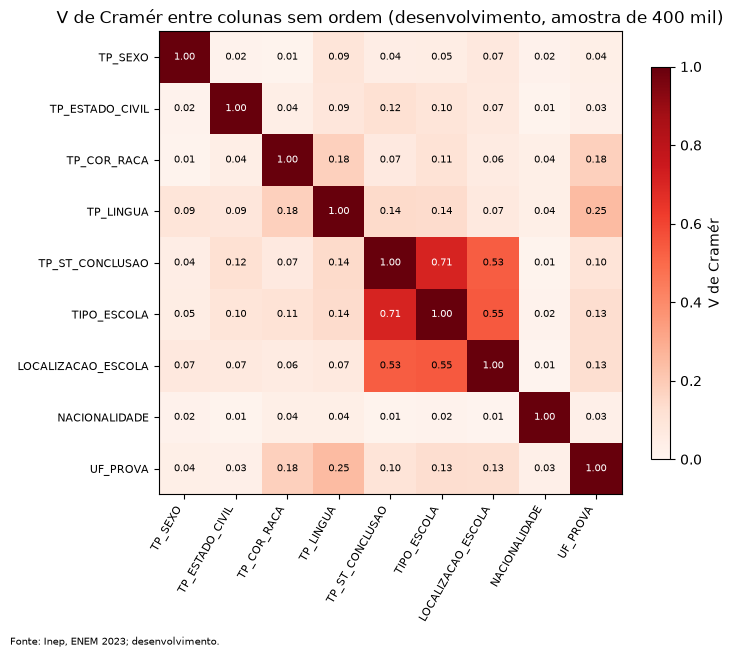

Pares com V > 0,7: 1 | maiores pares:
       coluna_1           coluna_2  V_de_Cramer
TP_ST_CONCLUSAO        TIPO_ESCOLA        0.707
    TIPO_ESCOLA LOCALIZACAO_ESCOLA        0.546
TP_ST_CONCLUSAO LOCALIZACAO_ESCOLA        0.534
      TP_LINGUA           UF_PROVA        0.249
    TP_COR_RACA          TP_LINGUA        0.178
    TP_COR_RACA           UF_PROVA        0.176
      TP_LINGUA    TP_ST_CONCLUSAO        0.143
      TP_LINGUA        TIPO_ESCOLA        0.138


In [3]:
from scipy.stats import chi2_contingency

rng = np.random.default_rng(SEMENTE)
am = rng.choice(len(X), min(400_000, len(X)), replace=False)
Xa = X.iloc[am]
cat = pd.DataFrame({
    "TP_SEXO": Xa["TP_SEXO"], "TP_ESTADO_CIVIL": Xa["TP_ESTADO_CIVIL"], "TP_COR_RACA": Xa["TP_COR_RACA"], "TP_LINGUA": Xa["TP_LINGUA"],
    "TP_ST_CONCLUSAO": Xa["TP_ST_CONCLUSAO"],
    "TIPO_ESCOLA": np.where(Xa["ESCOLA_PUBLICA"] == 1, "publica", np.where(Xa["ESCOLA_PRIVADA"] == 1, "privada", "sem informacao")),
    "LOCALIZACAO_ESCOLA": np.where(Xa["LOC_URBANA"] == 1, "urbana", np.where(Xa["LOC_RURAL"] == 1, "rural", "sem informacao")),
    "NACIONALIDADE": np.select([Xa["NAC_NAO_INFORMADO"] == 1, Xa["NAC_NATURALIZADO"] == 1, Xa["NAC_ESTRANGEIRO"] == 1, Xa["NAC_NATO_EXTERIOR"] == 1],
                               ["nao informado", "naturalizado", "estrangeiro", "nato exterior"], "brasileiro"),
    "UF_PROVA": np.select([Xa[c] == 1 for c in COLS if c.startswith("UF_")], [c for c in COLS if c.startswith("UF_")], "UF_SP")}).astype(str)


def cramer_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t, correction=False)[0]
    n = t.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * (min(t.shape) - 1)))) if min(t.shape) > 1 else np.nan


nomes = list(cat.columns)
V = pd.DataFrame(np.eye(len(nomes)), index=nomes, columns=nomes)
for i, a in enumerate(nomes):
    for b in nomes[i + 1:]:
        V.loc[a, b] = V.loc[b, a] = cramer_v(cat[a], cat[b])
V.round(3).to_csv(RES / "tabelas" / "e2_cramer_v_matriz.csv")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(V.values, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(nomes)), nomes, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(nomes)), nomes, fontsize=8)
for i in range(len(nomes)):
    for j in range(len(nomes)):
        ax.text(j, i, f"{V.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if V.values[i, j] > 0.6 else "black")
plt.colorbar(im, ax=ax, shrink=0.8, label="V de Cramér")
ax.set_title("V de Cramér entre colunas sem ordem (desenvolvimento, amostra de 400 mil)")
fig.text(0.01, 0.005, "Fonte: Inep, ENEM 2023; desenvolvimento.", fontsize=7)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(RES / "figuras" / "e2_cramer_v.png", dpi=150)
plt.show()
tri = V.where(np.triu(np.ones(V.shape, dtype=bool), k=1)).stack().rename("V_de_Cramer").reset_index()
tri.columns = ["coluna_1", "coluna_2", "V_de_Cramer"]
tri = tri.reindex(tri["V_de_Cramer"].sort_values(ascending=False).index)
tri.round(3).to_csv(RES / "tabelas" / "e2_cramer_v_pares.csv", index=False)
print(f"Pares com V > 0,7: {int((tri['V_de_Cramer'] > 0.7).sum())} | maiores pares:")
print(tri.head(8).round(3).to_string(index=False))

## 3. Município da prova com `TargetEncoder` dentro do Pipeline

**Hipótese.** O município da prova (cerca de 5 mil códigos) acrescenta informação de contexto que a UF não tem. Como tem muitas categorias, o one-hot é inviável; usamos a **média da nota por município**, que é uma codificação **supervisionada** e por isso só pode ser aprendida **sem o próprio alvo**: o `TargetEncoder` do scikit-learn faz isso por validação cruzada interna (5 partes) e fica **dentro do Pipeline**, então em cada dobra só enxerga o treino. Municípios que não aparecem no treino recebem a média geral. Comparamos com a mesma representação sem o município (a referência é o experimento `S2_com_uf` do notebook 04, Gradient Boosting inicial).

In [4]:
H3 = "O município da prova acrescenta contexto que a UF não tem."
pre_mun = ColumnTransformer([("mun", TargetEncoder(target_type="continuous", cv=KFold(n_splits=5, shuffle=True, random_state=SEMENTE)), ["MUN_PROVA"])], remainder="passthrough")
rodar("E3_com_municipio_TE", Pipeline([("pre", pre_mun), ("regressor", hgb_inicial())]), COLS + ["MUN_PROVA"], "E3 município da prova", H3,
      "TargetEncoder (média da nota por município, cv=5 interno) dentro do Pipeline; 74 colunas + município", "HistGradientBoosting (configuração inicial)",
      "lr=0.1, max_iter=300, folhas=31, leaf=200", ref="S2_com_uf")
rodar("E3_sem_municipio", Pipeline([("regressor", hgb_inicial())]), COLS, "E3 município da prova", H3, "74 colunas, sem município (refeito aqui para ter o mesmo ambiente)",
      "HistGradientBoosting (configuração inicial)", "lr=0.1, max_iter=300, folhas=31, leaf=200", ref="S2_com_uf")
reg.exp.loc[[i for i in ("S2_com_uf", "E3_sem_municipio", "E3_com_municipio_TE") if i in reg.exp.index], ["RMSE_media", "RMSE_desvio", "tempo_s", "conclusao"]]

E3_com_municipio_TE: RMSE 105.730 ± 0.171 | R² 0.355 | 25 s por dobra | RMSE -0.295 em relação a S2_com_uf: melhora (maior que o desvio entre dobras, 0.188).


E3_sem_municipio: RMSE 106.025 ± 0.188 | R² 0.351 | 27 s por dobra | RMSE +0.000 em relação a S2_com_uf: sem diferença clara (dentro do desvio entre dobras, 0.188).


,RMSE_media,RMSE_desvio,tempo_s,conclusao
id,,,,
S2_com_uf,106.024983,0.187584,39.934462,RMSE -0.701 em relação a S1b_colunas_separadas...
E3_sem_municipio,106.024983,0.187584,27.043157,RMSE +0.000 em relação a S2_com_uf: sem difere...
E3_com_municipio_TE,105.729637,0.170940,25.330086,RMSE -0.295 em relação a S2_com_uf: melhora (m...


## 4. Sementes do modelo final

O desvio entre dobras mede a variação por dobra, **não por semente**. Aqui o Gradient Boosting final (hiperparâmetros da busca) é repetido com 3 sementes (0, 1 e 2; a semente muda a parcela interna do treino usada pela parada antecipada). A semente 42 é a do experimento `F_final_cv` do notebook 04.

In [5]:
for s in (0, 1, 2):
    rodar(f"E4_semente_{s}", Pipeline([("regressor", hgb(random_state=s, **PARAMS_BUSCA))]), COLS, "E4 sementes",
          "O erro da solução final varia pouco entre sementes.", "74 colunas, sem seleção, PCA nem pesos", "HistGradientBoosting (hiperparâmetros da busca)",
          f"{PARAMS_BUSCA}; random_state={s}")
ref_seed = reg.exp.loc[[i for i in ["F_final_cv", "E4_semente_0", "E4_semente_1", "E4_semente_2"] if i in reg.exp.index], ["RMSE_media", "RMSE_desvio", "R2_media", "tempo_s"]].astype(float)
ref_seed.index = ["semente 42 (notebook 04)", "semente 0", "semente 1", "semente 2"][: len(ref_seed)]
rm = ref_seed["RMSE_media"]
print(f"RMSE médio entre as sementes: {rm.mean():.3f}; desvio entre sementes: {rm.std():.3f}; amplitude: {rm.max() - rm.min():.3f}")
ref_seed.round(3)

E4_semente_0: RMSE 105.862 ± 0.182 | R² 0.353 | 60 s por dobra | 


E4_semente_1: RMSE 105.871 ± 0.192 | R² 0.353 | 55 s por dobra | 


E4_semente_2: RMSE 105.868 ± 0.184 | R² 0.353 | 61 s por dobra | 


RMSE médio entre as sementes: 105.866; desvio entre sementes: 0.004; amplitude: 0.009


,RMSE_media,RMSE_desvio,R2_media,tempo_s
semente 42 (notebook 04),105.864,0.169,0.353,91.207
semente 0,105.862,0.182,0.353,59.851
semente 1,105.871,0.192,0.353,55.081
semente 2,105.868,0.184,0.353,61.231


## 5. Busca de hiperparâmetros na representação final

A busca do notebook 02 otimizado foi feita no dataset de 30 colunas. Aqui repetimos a `RandomizedSearchCV` (10 configurações, 3 dobras, mesmos espaços, semente 42) na **representação final de 74 colunas**, nos três melhores regressores distintos entre os que podem ser buscados: Gradient Boosting, bagging e Random Forest. **Como o teste já foi aberto, o resultado não substitui a solução final**: serve para medir quanto a busca antiga deixou de ganhar.

In [6]:
def buscar(modelo, espaco, nome, id_exp):
    if reg.tem_dobras(id_exp):
        print(f"{id_exp}: já feito"); return None
    metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
    b = RandomizedSearchCV(modelo, espaco, n_iter=N_ITER, cv=dobras, scoring=metricas, refit=False, random_state=SEMENTE, n_jobs=1)
    t0 = time.time()
    b.fit(X[COLS], y)
    r = pd.DataFrame(b.cv_results_)
    r.to_csv(RES / "tabelas" / f"e5_busca_representacao_final_{id_exp.split('_', 1)[1]}.csv", index=False)
    i = int(r["rank_test_RMSE"].idxmin())
    d = pd.DataFrame({"RMSE": [-r.loc[i, f"split{k}_test_RMSE"] for k in range(3)], "MAE": [-r.loc[i, f"split{k}_test_MAE"] for k in range(3)],
                      "R2": [r.loc[i, f"split{k}_test_R2"] for k in range(3)], "tempo_s": r.loc[i, "mean_fit_time"] + r.loc[i, "mean_score_time"]})
    reg.gravar(id_exp, d, secao="E5 busca na representação final", hipotese="A busca feita no dataset de 30 colunas deixou ganho na representação final.",
               features="74 colunas", preparacao="74 colunas, sem seleção, PCA nem pesos", modelo=nome, parametros=str(b.cv_results_["params"][i]),
               avaliado="validação cruzada (3 dobras) no desenvolvimento", n_features=len(COLS),
               conclusao=f"Melhor de {N_ITER} configurações em {(time.time() - t0) / 60:.0f} min (RMSE otimista: é o melhor entre {N_ITER}). Não substitui a solução final: o teste já foi aberto.")
    print(f"{nome}: melhor RMSE {d['RMSE'].mean():.3f} ± {d['RMSE'].std():.3f} em {(time.time() - t0) / 60:.1f} min | parâmetros: {b.cv_results_['params'][i]}", flush=True)
    return r


buscar(hgb(), {"learning_rate": loguniform(0.02, 0.3), "max_iter": [200, 300, 500], "max_leaf_nodes": randint(15, 100),
               "min_samples_leaf": randint(50, 500), "l2_regularization": loguniform(1e-3, 10)}, "Gradient Boosting", "E5_gb_busca")
buscar(BaggingRegressor(estimator=DecisionTreeRegressor(random_state=SEMENTE), bootstrap=True, n_jobs=-1, random_state=SEMENTE),
       {"n_estimators": randint(10, 41), "max_samples": [0.5, 0.7, 1.0], "max_features": [0.6, 0.8, 1.0],
        "estimator__max_depth": randint(6, 16), "estimator__min_samples_leaf": randint(20, 200)}, "Bagging", "E5_bagging_busca")
buscar(RandomForestRegressor(n_jobs=-1, random_state=SEMENTE),
       {"n_estimators": [50, 100], "max_depth": randint(8, 16), "min_samples_leaf": randint(10, 200), "max_features": [0.3, 0.5, 0.7]}, "Random Forest", "E5_rf_busca")
ids_e5 = [i for i in ("F_final_cv", "E5_gb_busca", "E5_bagging_busca", "E5_rf_busca") if i in reg.exp.index]
reg.exp.loc[ids_e5, ["RMSE_media", "RMSE_desvio", "R2_media", "tempo_s", "parametros"]]

Gradient Boosting: melhor RMSE 105.859 ± 0.181 em 22.4 min | parâmetros: {'l2_regularization': np.float64(0.029204338471814112), 'learning_rate': np.float64(0.06877172495876586), 'max_iter': 500, 'max_leaf_nodes': 76, 'min_samples_leaf': 100}


Bagging: melhor RMSE 107.878 ± 0.172 em 16.6 min | parâmetros: {'estimator__max_depth': 15, 'estimator__min_samples_leaf': 34, 'max_features': 0.8, 'max_samples': 0.7, 'n_estimators': 24}


Random Forest: melhor RMSE 107.919 ± 0.192 em 67.9 min | parâmetros: {'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 30, 'n_estimators': 50}


,RMSE_media,RMSE_desvio,R2_media,tempo_s,parametros
id,,,,,
F_final_cv,105.864137,0.168507,0.353211,91.206923,"{'l2_regularization': 0.24400607090817547, 'le..."
E5_gb_busca,105.859218,0.180684,0.353271,66.465371,{'l2_regularization': np.float64(0.02920433847...
E5_bagging_busca,107.878222,0.171703,0.328367,40.516979,"{'estimator__max_depth': 15, 'estimator__min_s..."
E5_rf_busca,107.918962,0.191728,0.327859,38.975856,"{'max_depth': 15, 'max_features': 0.3, 'min_sa..."


## 6. Dataset 5 (solução independente) por validação cruzada

O dataset 5 é a definição de entradas da solução independente de outra IA: **41 colunas categóricas originais** (inclusive `TP_ENSINO`, `SG_UF_ESC`, `TP_DEPENDENCIA_ADM_ESC` e `TP_SIT_FUNC_ESC`, que o nosso não usa) e **4 derivadas**, com one-hot de todas as categóricas dentro do Pipeline. O script dela está arquivado em `resultados/dataset5_replicacao_independente/`; a preparação é a mesma (a função `load_data` do script). Aqui os modelos de ajuste rápido passam pela **mesma validação cruzada** que os nossos (Random Forest, bagging, pasting, árvore e AdaBoost não são refeitos: o Random Forest sozinho levou mais de uma hora e meia no ajuste dela).

In [7]:
sys.path.insert(0, "../resultados/dataset5_replicacao_independente")
import treino_enem as t5
from sklearn.svm import LinearSVR

X5, y5, meta5 = t5.load_data(Path("../dados/raw/DADOS/MICRODADOS_ENEM_2023.csv"))
ids5 = pd.Series(meta5.pop("ids"))
assert (ids5.astype("int64").to_numpy() == ids.to_numpy()).all(), "as linhas do dataset 5 não estão na ordem de ids_elegiveis.csv"
X5 = X5[em_dev].reset_index(drop=True)
y5 = pd.Series(y5[em_dev]).reset_index(drop=True)
if SMOKE:
    X5, y5 = X5.iloc[amostra].reset_index(drop=True), y5.iloc[amostra].reset_index(drop=True)
assert np.allclose(y5.to_numpy(), y.to_numpy())
print(f"dataset 5: {X5.shape[0]:,} pessoas no desenvolvimento, {X5.shape[1]} colunas de entrada")

modelos5 = {
    "regressao_linear": ("Regressão linear (sem regularização)", Pipeline([("prep", t5.make_preprocessor(X5)), ("model", LinearRegression())]), "sem hiperparâmetros"),
    "ridge": ("Ridge", Pipeline([("prep", t5.make_preprocessor(X5)), ("model", Ridge(alpha=10.0, solver="lsqr"))]), "alpha=10, solver=lsqr"),
    "svr_linear": ("SVR linear (LinearSVR)", Pipeline([("prep", t5.make_preprocessor(X5)), ("model", LinearSVR(C=0.1, dual="auto", max_iter=1000, random_state=SEMENTE))]), "C=0,1"),
    "gradient_boosting": ("Gradient Boosting leve (50 árvores)", Pipeline([("prep", t5.make_preprocessor(X5, "ordinal")), ("model", HistGradientBoostingRegressor(
        max_iter=50, max_leaf_nodes=15, l2_regularization=1.0, early_stopping=False, random_state=SEMENTE))]), "50 árvores, 15 folhas, l2=1"),
}
for chave, (nome, pipe, par) in modelos5.items():
    id_exp = f"E6_dataset5_{chave}"
    if reg.tem_dobras(id_exp):
        print(f"{id_exp}: já feito"); continue
    d = cv_dobras(pipe, X5, y5, dobras)
    reg.gravar(id_exp, d, secao="E6 dataset 5 por validação cruzada", hipotese="A preparação da solução independente (one-hot de tudo) tem desempenho parecido nas mesmas dobras.",
               features=f"{X5.shape[1]} colunas de entrada (dataset 5)", preparacao="41 categóricas originais + 4 derivadas; one-hot dentro do Pipeline (ordinal no Gradient Boosting)",
               modelo=nome, parametros=par, avaliado="validação cruzada (3 dobras) no desenvolvimento", n_features=X5.shape[1],
               conclusao="Replicação: mesma preparação da outra IA, agora nas nossas dobras.")
    print(f"{nome}: RMSE {d['RMSE'].mean():.3f} ± {d['RMSE'].std():.3f} | R² {d['R2'].mean():.3f} | {d['tempo_s'].mean():.0f} s por dobra", flush=True)
ids_e6 = [f"E6_dataset5_{c}" for c in modelos5 if f"E6_dataset5_{c}" in reg.exp.index]
tab_e6 = reg.exp.loc[ids_e6 + [i for i in ("F_regressao_linear_cv", "F_final_cv") if i in reg.exp.index], ["RMSE_media", "RMSE_desvio", "MAE_media", "R2_media", "tempo_s"]].astype(float).round(3)
tab_e6.to_csv(RES / "tabelas" / "e6_dataset5_validacao_cruzada.csv")
tab_e6

dataset 5: 2,153,941 pessoas no desenvolvimento, 45 colunas de entrada


Regressão linear (sem regularização): RMSE 111.287 ± 2.393 | R² 0.285 | 39 s por dobra


Ridge: RMSE 107.508 ± 0.197 | R² 0.333 | 15 s por dobra


SVR linear (LinearSVR): RMSE 107.903 ± 0.206 | R² 0.328 | 18 s por dobra


Gradient Boosting leve (50 árvores): RMSE 107.992 ± 0.210 | R² 0.327 | 7 s por dobra


,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s
id,,,,,
E6_dataset5_regressao_linear,111.287,2.393,84.203,0.285,38.531
E6_dataset5_ridge,107.508,0.197,83.599,0.333,15.170
E6_dataset5_svr_linear,107.903,0.206,83.298,0.328,17.585
E6_dataset5_gradient_boosting,107.992,0.210,84.353,0.327,7.083
F_regressao_linear_cv,108.868,0.162,84.862,0.316,2.803
F_final_cv,105.864,0.169,82.025,0.353,91.207


## Resumo

Todos os resultados deste notebook estão em `resultados/experimentos.csv` (ids `E1_*` a `E6_*`) e nas tabelas `resultados/tabelas/e*_*.csv`. Nenhum deles altera a solução final nem o teste.